<a href="https://colab.research.google.com/github/RiazullJannat/DL/blob/main/ann_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [42]:
import pandas as pd
from sklearn.model_selection import train_test_split
import torch
from torch.utils.data import Dataset, DataLoader
import torch.optim as optim
import matplotlib.pyplot as plt
import torch.nn as nn

In [43]:
torch.manual_seed(42)

In [44]:
device = torch.device("cuda" if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


In [45]:
df = pd.read_csv("./sample_data/mnist_train_small.csv")
df

,6,0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,...,0.581,0.582,0.583,0.584,0.585,0.586,0.587,0.588,0.589,0.590
0,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,7,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19994,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
19995,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
19996,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
19997,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


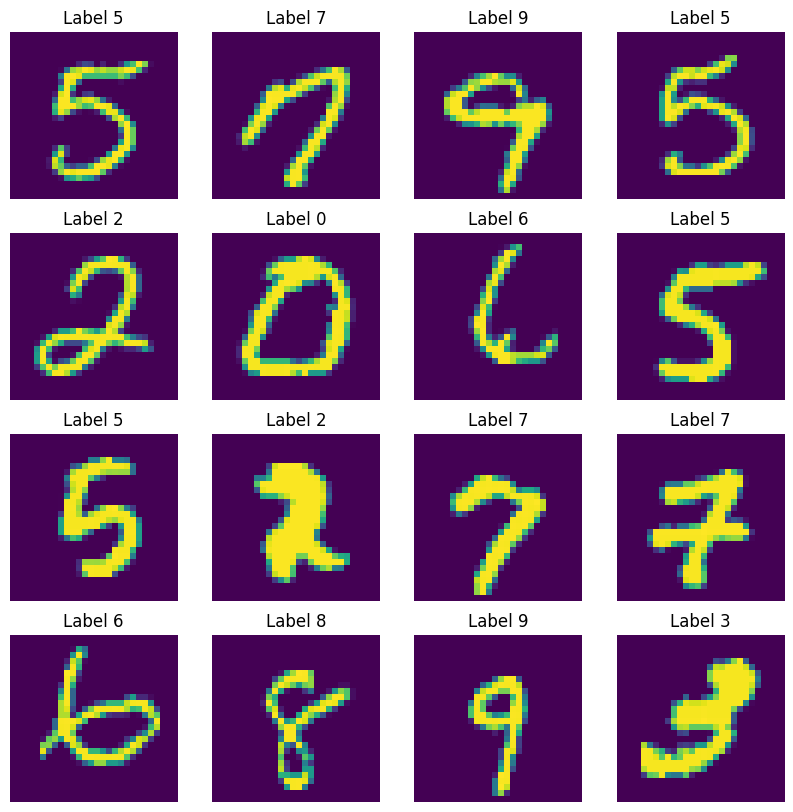

In [46]:
fig, axes = plt.subplots(4,4, figsize=(10,10))

axes = axes.flatten()

for i, ax in enumerate(axes):
  im = df.iloc[i,1:].values.reshape(28,28)
  ax.imshow(im)
  ax.axis("off")
  ax.set_title(f"Label {df.iloc[i,0]}")

In [47]:
X = df.iloc[:,1:].values / 255.0
y = df.iloc[:,0].values
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)


In [48]:
class CustomDataset(Dataset):
  def __init__(self, features, labels):
    self.features = torch.tensor(features, dtype = torch.float32)
    self.lables = torch.tensor(labels, dtype = torch.long)

  def __len__(self):
    return len(self.features)

  def __getitem__(self, index):
    return self.features[index], self.lables[index]

In [49]:
train_dataset = CustomDataset(X_train, y_train)
test_dataset = CustomDataset(X_test, y_test)

In [50]:
#loader
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, pin_memory = True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, pin_memory = True)

In [51]:
from torch.nn.modules.activation import ReLU
#define NN class
class MyNN(nn.Module):
  def __init__(self, num_features):
    super().__init__()
    self.model = nn.Sequential(
        nn.Linear(num_features, 128),
        nn.ReLU(),
        nn.Linear(128, 64),
        nn.ReLU(),
        nn.Linear(64,10)

    )

  def forward(self, X):
    return self.model(X)

In [52]:
#initate model
epoches = 10
learning_rate = 0.1


In [53]:
model = MyNN(X_train.shape[1])
model = model.to(device)
print(model)

MyNN(
  (model): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=10, bias=True)
  )
)


In [54]:
# loss function
criterion = nn.CrossEntropyLoss()

In [55]:
#optimizers
optimizer = optim.SGD(model.parameters(),learning_rate)

In [56]:
len(train_loader)

500

In [57]:
#training loop

for epoch in range(epoches):
  total_epoch_loss = 0.0
  for batch_features, batch_labels in train_loader:
    #move to gpu
    batch_features, batch_labels = batch_features.to(device), batch_labels.to(device)
    #forward pass
    output = model(batch_features)
    #loss
    loss = criterion(output, batch_labels)
    #back pass
    optimizer.zero_grad()
    loss.backward()
    #update weights
    optimizer.step()
    total_epoch_loss+=loss.item()
  print(f"avg loss per epoch -> {(total_epoch_loss / len(train_loader)):.4f}")

avg loss per epoch -> 0.6956
avg loss per epoch -> 0.2743
avg loss per epoch -> 0.1974
avg loss per epoch -> 0.1516
avg loss per epoch -> 0.1174
avg loss per epoch -> 0.0917
avg loss per epoch -> 0.0738
avg loss per epoch -> 0.0579
avg loss per epoch -> 0.0461
avg loss per epoch -> 0.0356


In [59]:
model.eval()

total = 0.0
correct = 0.0

with torch.no_grad():
  for batch_features, batch_labels in test_loader:
    batch_features, batch_labels = batch_features.to(device), batch_labels.to(device)

    outputs = model(batch_features)

    _, predicted = torch.max(outputs, 1)

    total += batch_labels.size(0)

    # check how many predictions matched the ground truth labels
    correct += (predicted == batch_labels).sum().item()

accuracy = (correct / total) * 100
print(f"total number: {total}")
print(f"correct prediction: {correct:.0f}")
print(f"accuracy: {accuracy:.2f}%")

total number: 4000.0
correct prediction: 3860
accuracy: 96.50%
